# 250-year Seismic vs Geodetic moment budgets (Fig. 5)

| Panel | Content | Axes |
|---|---|---|
| **a** | Cumulative seismic moment vs. geodetic / on-fault / UCERF3 moment | time × cumulative moment |
| **b** | Simulated null distributions of the cumulative moment released over the catalogue window, for five earthquake-occurrence models | probability density × cumulative moment (**y-axis shared with a**) |
| **c** | Expanding-window seismic moment rate | time (shared with a) × moment rate |

## Approach

* **Magnitude of completeness $M_c = 3.5$** everywhere, see [Mueller (2018)](https://doi.org/10.1785/0220170108): the observed cumulative moment (panels a, c),
  the observed test statistic $S_{\rm obs}$, the tapered-Pareto fit, and the lower bound of every
  sampled magnitude distribution. 
* $\log_{10} M_0\,[{\rm N\,m}] = 1.5\,M_w + 9.1$.
* Null hypothesis: the long-term seismic moment rate equals the **midpoint of this study's total geodetic
  moment-rate range**, $G_{\rm true}=\dot M_{\rm geo}=(\dot M_{\rm geo}^{\min}+\dot M_{\rm geo}^{\max})/2$
  $=3.39\times10^{19}$ N m/yr, so panel b's expectation $G_{\rm true}T$ sits in the middle of panel a's geodetic
  band at $t=T_{\rm obs}$. The same midpoint is used for the seismic/geodetic ratio.
* Event rate from the budget only: $\lambda = G_{\rm true}/E[M_0]$. 

## Terminology: maximum magnitude vs. corner magnitude

These are different parameters of different models and are never interchanged here:

| Model | Upper-tail parameter | Meaning | Survival function in moment, $M \ge M_t$ |
|---|---|---|---|
| Truncated Gutenberg–Richter (truncated Pareto in moment) | **maximum magnitude** $M_{\max}$ (moment $M_{0,\max}$) | hard cutoff, $P(M_w > M_{\max}) = 0$ | $\dfrac{(M_t/M)^{\beta} - (M_t/M_{0,\max})^{\beta}}{1-(M_t/M_{0,\max})^{\beta}}$ |
| Tapered Pareto (Kagan 2002) | **corner magnitude** $m_{\rm cm}$ (corner moment $M_{\rm cm}$) | onset of an exponential taper, **no maximum** | $(M_t/M)^{\beta}\exp\!\big((M_t-M)/M_{\rm cm}\big)$ |

$M_t = 10^{1.5 M_c + 9.1}$ is the threshold moment at $M_c$, and $\beta = b/1.5$ links the moment-space
Pareto index to the GR $b$-value. The corner magnitude is written $m_{\rm cm}$, not $M_c$, because $M_c$ is
reserved for the magnitude of completeness.

## Inputs, observed moment budget ($M_w \geq M_c$) and rates


In [1]:
import json
import os
import sys
import time

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.path import Path
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.transforms import blended_transform_factory
from matplotlib.ticker import FuncFormatter

# Helper functions for the Monte Carlo null test (run from Natgeo_supplements/Notebooks)
sys.path.insert(0, "../Input_data/modules")
import moment_null_mc as mnm  # noqa: E402


# ============================================================
# FILES
# ============================================================

# Inputs are read from ../Input_data; all outputs go to ../output_data/catalog_analysis_mcmc.
CATALOGUE_PATH = "../Input_data/datasets/earthquake_catalog/wmm_wg.c2"
POLYGON_PATH = "../Input_data/focal_mechanisms/California_strain_polygon.gmt"
TRADE_OFF_PATH = "../Input_data/trade_off/natgeo_tradeoff_surface_CALI_bodyforce_moment.csv"
OUTPUT_DIR = "../output_data/catalog_analysis_mcmc"

OUT_PNG = os.path.join(OUTPUT_DIR, "mueller_c2_california_three_panel_mc_null.png")
OUT_PDF = os.path.join(OUTPUT_DIR, "mueller_c2_california_three_panel_mc_null.pdf")

# ------------------------------------------------------------
# Magnitude of completeness: FIXED at Mc = 3.5 for the whole
# analysis (observed moment, rates, model fits and sampling).
# ------------------------------------------------------------
MC_COMPLETENESS = 3.5

# load csv file with tradeoff data
trade_off_df = pd.read_csv(TRADE_OFF_PATH)

os.makedirs(OUTPUT_DIR, exist_ok=True)

T_START = time.time()


# ============================================================
# GEODETIC MOMENT-RATE CONSTRAINT
# ============================================================

# Parameter grid
log_s = np.logspace(-1, 1, 10)

wm_all = log_s[6]

ws_best, ws_lower, ws_upper = log_s[[4, 0, 9]]
wb_best, wb_lower, wb_upper = log_s[[3, 2, 4]]

def get_row(df, wm, ws, wb, atol=1e-9):
    mask = (
        np.isclose(df["weight_moment"], wm, atol=atol, rtol=0)
        & np.isclose(df["weight_smooth"], ws, atol=atol, rtol=0)
        & np.isclose(df["weight_bottom"], wb, atol=atol, rtol=0)
    )

    rows = df.loc[mask]

    if len(rows) != 1:
        raise ValueError(f"Expected 1 matching row, found {len(rows)}")

    return rows.iloc[0]

best_row = get_row(trade_off_df, wm_all, ws_best, wb_best)
lower_bound_row = get_row(trade_off_df, wm_all, ws_lower, wb_lower)
upper_bound_row = get_row(trade_off_df, wm_all, ws_upper, wb_upper)

best_model = best_row[["Mo_on_fault_inpoly_Nm_per_yr", "Mo_off_ss_inpoly_Nm_per_yr", "Mo_total_ss_inpoly_Nm_per_yr"]]
lower_bound_model = lower_bound_row[["Mo_on_fault_inpoly_Nm_per_yr", "Mo_off_ss_inpoly_Nm_per_yr", "Mo_total_ss_inpoly_Nm_per_yr"]]
upper_bound_model = upper_bound_row[["Mo_on_fault_inpoly_Nm_per_yr", "Mo_off_ss_inpoly_Nm_per_yr", "Mo_total_ss_inpoly_Nm_per_yr"]]

# Total geodetic range from the two bounding models. The "lower-bound" model
# (minimum smoothing weight, which minimizes off-fault deformation) has the larger total moment rate, so we take min/max
# rather than relying on the model names to avoid confusing myself later... as often happens when I revisit my codes after some time.
_geo_a = lower_bound_model["Mo_total_ss_inpoly_Nm_per_yr"]
_geo_b = upper_bound_model["Mo_total_ss_inpoly_Nm_per_yr"]
GEO_LOWER = min(_geo_a, _geo_b)
GEO_UPPER = max(_geo_a, _geo_b)

# Reference geodetic rate = midpoint of the range. Used for the
# seismic / geodetic ratio, the panel-c label and the Monte Carlo null.
GEO_RATE = (GEO_LOWER + GEO_UPPER) / 2.0  # N m/yr

# Best-fit total (not plotted; printed for reference only)
GEO_BEST = best_model["Mo_total_ss_inpoly_Nm_per_yr"]

GEO_RATE_UCERF3 = 2.7967e19 # N m/yr, from UCERF3, mean from Table 5 (Field et al., 2014)

# On-fault moment rate (best fit kept for the summary only)
ONFAULT_RATE = best_model["Mo_on_fault_inpoly_Nm_per_yr"]

# On-fault uncertainty range from the lower/upper-bound models.
# min/max guards against the lower-bound model not giving the
# smaller on-fault value.
_onfault_a = lower_bound_model["Mo_on_fault_inpoly_Nm_per_yr"]
_onfault_b = upper_bound_model["Mo_on_fault_inpoly_Nm_per_yr"]
ONFAULT_LOWER = min(_onfault_a, _onfault_b)
ONFAULT_UPPER = max(_onfault_a, _onfault_b)

ONFAULT_RATE_UCERF3 = 1.8533e19  # N m/yr, from UCERF3 (Field et al., 2014)

# Off-fault range (printed only)
_off_a = lower_bound_model["Mo_off_ss_inpoly_Nm_per_yr"]
_off_b = upper_bound_model["Mo_off_ss_inpoly_Nm_per_yr"]
OFFFAULT_LOWER = min(_off_a, _off_b)
OFFFAULT_UPPER = max(_off_a, _off_b)

# ============================================================
# COLOUR PALETTE
# ============================================================

SEISMIC_COLOR = "#222222"
SEISMIC_FILL = "#727171"

GEODETIC_COLOR = "#A32C2C"
GEODETIC_FILL = "#CA9999"
UCERF3_ONFAULT_FILL = "#BD9525"   # UCERF3 on-fault moment rate
#UCERF3_GEO_RATE_FILL = "#631250"  # UCERF3 total geodetic moment rate
UCERF3_GEO_RATE_FILL = "#12632C"  # UCERF3 total geodetic moment rate

# Line styles for the UCERF3 reference rates (distinct from the
# solid, dash-dot and dashed lines already used)
UCERF3_GEO_LS = (0, (1, 1.5))                      # dotted
UCERF3_ONFAULT_LS = (0, (6, 1.5, 1, 1.5, 1, 1.5))  # dash-dot-dot

AVG_RATE_COLOR = "#4A78B5"   # seismic mean rate
ONFAULT_COLOR = "#F7D52A"    # on-fault moment rate
ONFAULT_COLOR_ANNOTATION = "#CEAC00"    # on-fault moment rate
ONFAULT_FILL = ONFAULT_COLOR # on-fault uncertainty band (yellow)
ONFAULT_ALPHA = 0.35

# Panel b: one colour per earthquake-occurrence model
# (palette checked for colour-vision-deficiency separation)
MODEL_COLORS = {
    "tgr_b0.8_mmax7.9": "#2F4B9A",
    "tgr_b0.8_mmax8.5": "#8B5FBF",
    "tgr_b1.0_mmax7.9": "#00908A",
    "tapered_pareto_mle": "#C8691C",
    "tgr_b1.0_mmax8.3": "#EA089B",
}

GRID_COLOR = "#E2E2E2"
ANNOTATION_COLOR = "#303030"
LEADER_COLOR = "#999999"
TEXT_GREY = "#666666"
TEXT_GREY_ANNOTATION = "#1B1B1B"


# ============================================================
# LOAD C2 CATALOGUE
# ============================================================

rows = []

with open(CATALOGUE_PATH, "r", errors="replace") as f:

    next(f)

    for line in f:

        p = line.split()

        if len(p) < 13:
            continue

        try:
            rows.append([
                float(p[0]),   # Mw
                float(p[1]),   # Longitude
                float(p[2]),   # Latitude
                float(p[3]),   # Depth_km
                int(p[4]),     # Year
                int(p[5]),     # Month
                int(p[6]),     # Day
                int(p[7]),     # Hour
                int(p[8]),     # Minute
                float(p[9]),   # Second
                float(p[10]),  # Sigma_m
                float(p[11]),  # Mwe
                float(p[12]),  # Nstar
            ])

        except ValueError:
            pass


cols = [
    "Mw", "Longitude", "Latitude", "Depth_km",
    "Year", "Month", "Day", "Hour", "Minute", "Second",
    "Sigma_m", "Mwe", "Nstar",
]

df = pd.DataFrame(rows, columns=cols)


# ============================================================
# LOAD CALIFORNIA POLYGON
# ============================================================

ca_poly = np.loadtxt(POLYGON_PATH)

inside = Path(ca_poly).contains_points(
    df[["Longitude", "Latitude"]].to_numpy()
)

cal = df.loc[inside].copy()


# ============================================================
# CREATE DATES
# ============================================================

cal["date"] = pd.to_datetime(
    dict(
        year=cal["Year"],
        month=cal["Month"].clip(1, 12),
        day=cal["Day"].clip(1, 28),
    ),
    errors="coerce",
)

cal = (
    cal
    .dropna(subset=["date"])
    .sort_values("date")
    .copy()
)


# ============================================================
# MAGNITUDE OF COMPLETENESS (Mc = 3.5)
# ============================================================

# All in-polygon events define the observation window only.
# Every moment / rate statistic below uses Mw >= Mc events, the
# same population the Monte Carlo models generate.

cal_all = cal

cal = (
    cal_all
    .loc[cal_all["Mw"] >= MC_COMPLETENESS]
    .copy()
)


# ============================================================
# SCALAR SEISMIC MOMENT
# ============================================================

# log10(M0) = 1.5 Mw + 9.1
# M0 in N m

cal["M0_Nm"] = 10 ** (1.5 * cal["Mw"] + 9.1)

cal["cum_M0_Nm"] = cal["M0_Nm"].cumsum()


# ============================================================
# CUMULATIVE SEISMIC MOMENT UNCERTAINTY
# ============================================================

# Propagate each event's magnitude uncertainty (Sigma_m)
# into a moment uncertainty:
#
# sigma_M0 = ln(10) * 1.5 * M0 * sigma_Mw
#
# Assuming independent per-event errors, cumulative
# variance is the running sum of sigma_M0**2.

cal["M0_sigma_Nm"] = (
    np.log(10)
    * 1.5
    * cal["M0_Nm"]
    * cal["Sigma_m"]
)

cal["cum_M0_variance"] = (
    cal["M0_sigma_Nm"] ** 2
).cumsum()

cal["cum_M0_sigma"] = np.sqrt(
    cal["cum_M0_variance"]
)


# ============================================================
# TIME SINCE FIRST EVENT
# ============================================================

t0 = cal_all["date"].iloc[0]

elapsed = (
    cal["date"] - t0
).dt.total_seconds() / (365.2425 * 24 * 3600)

duration = (
    cal_all["date"].iloc[-1] - t0
).total_seconds() / (365.2425 * 24 * 3600)


# ============================================================
# FINAL FULL-CATALOGUE SEISMIC RATE
# ============================================================

total_moment = cal["M0_Nm"].sum()

seismic_rate_mean = (
    total_moment / duration
)

seismic_rate_sigma_final = (
    cal["cum_M0_sigma"].iloc[-1] / duration
)

seismic_geodetic_ratio = (
    seismic_rate_mean / GEO_RATE
)

seismic_percentage = (
    seismic_geodetic_ratio * 100.0
)


# ============================================================
# GEODETIC CUMULATIVE MOMENT (UNCERTAINTY RANGE ONLY)
# ============================================================

geo_moment_lower = GEO_LOWER * elapsed

geo_moment_upper = GEO_UPPER * elapsed


# ============================================================
# ON-FAULT CUMULATIVE MOMENT (UNCERTAINTY RANGE)
# ============================================================

onfault_moment_lower = ONFAULT_LOWER * elapsed

onfault_moment_upper = ONFAULT_UPPER * elapsed


# ============================================================
# CUMULATIVE SEISMIC UNCERTAINTY BAND
# ============================================================

cum_lower = np.maximum(
    cal["cum_M0_Nm"] - cal["cum_M0_sigma"],
    0.0
)

cum_upper = (
    cal["cum_M0_Nm"]
    + cal["cum_M0_sigma"]
)


# ============================================================
# MEAN SEISMIC-RATE LINE (PANEL A)
# ============================================================

# Straight line from the origin with slope = mean seismic rate.

avg_moment_line = (
    seismic_rate_mean
    * elapsed
)


# ============================================================
# UCERF3 REFERENCE LINES (PANEL A)
# ============================================================

ucerf3_geo_moment_line = GEO_RATE_UCERF3 * elapsed

ucerf3_onfault_moment_line = ONFAULT_RATE_UCERF3 * elapsed


# ============================================================
# EXPANDING-WINDOW SEISMIC MOMENT RATE
# ============================================================

start_year = int(
    cal["date"].dt.year.min()
)

end_year = int(
    cal["date"].dt.year.max()
)

rate_years = np.arange(
    start_year + 1,
    end_year + 1
)

rate_dates = pd.to_datetime(
    rate_years.astype(str) + "-07-01"
)

rate_elapsed = (
    rate_dates - t0
).total_seconds() / (365.2425 * 24 * 3600)


expanding_seismic_rate = np.full(
    len(rate_dates),
    np.nan
)

expanding_seismic_rate_sigma = np.full(
    len(rate_dates),
    np.nan
)


for i, current_date in enumerate(rate_dates):

    included = (
        cal["date"]
        <= current_date
    )

    moment_sum = cal.loc[
        included,
        "M0_Nm"
    ].sum()

    # Propagated magnitude-uncertainty variance
    variance_sum = (
        cal.loc[
            included,
            "M0_sigma_Nm"
        ] ** 2
    ).sum()

    T = rate_elapsed[i]

    if T <= 0:
        continue

    expanding_seismic_rate[i] = (
        moment_sum / T
    )

    expanding_seismic_rate_sigma[i] = (
        np.sqrt(variance_sum) / T
    )


# ============================================================
# RATE UNCERTAINTY
# ============================================================

rate_lower = np.maximum(
    expanding_seismic_rate
    - expanding_seismic_rate_sigma,
    0.0
)

rate_upper = (
    expanding_seismic_rate
    + expanding_seismic_rate_sigma
)


# ============================================================
# OBSERVED STATISTIC FOR THE NULL TEST
# ============================================================

# T_OBS: catalogue window; S_OBS: cumulative moment of Mw >= Mc events.
T_OBS = duration
S_OBS = total_moment

print(f"In-polygon events (all Mw):   {len(cal_all):,}")
print(f"In-polygon events (Mw >= {MC_COMPLETENESS}): {len(cal):,}")
print(f"T_obs = {T_OBS:.4f} yr   S_obs(Mw >= {MC_COMPLETENESS}) = {S_OBS:.4e} N m")
print(f"(all-magnitude total = {(10 ** (1.5 * cal_all['Mw'] + 9.1)).sum():.4e} N m; "
      f"events below Mc carry {100 * (1 - S_OBS / (10 ** (1.5 * cal_all['Mw'] + 9.1)).sum()):.3f}% of it)")

In-polygon events (all Mw):   68,786
In-polygon events (Mw >= 3.5): 10,340
T_obs = 247.4192 yr   S_obs(Mw >= 3.5) = 3.6528e+21 N m
(all-magnitude total = 3.6552e+21 N m; events below Mc carry 0.064% of it)


## Earthquake-occurrence models

| key | model | $b$ / $\beta$ | $M_c$ | upper tail |
|---|---|---|---|---|
| `tgr_b0.8_mmax7.9` | truncated GR (primary) | $b$ = 0.8 | 3.5 | maximum magnitude $M_{\max}$ = 7.9 (largest observed) |
| `tgr_b0.8_mmax8.5` | truncated GR ($M_{\max}$ sensitivity) | $b$ = 0.8 | 3.5 | maximum magnitude $M_{\max}$ = 8.5 |
| `tgr_b1.0_mmax7.9` | truncated GR ($b$ sensitivity) | $b$ = 1.0 | 3.5 | maximum magnitude $M_{\max}$ = 7.9 |
| `tgr_b1.0_mmax8.3` | truncated GR ($b$ and $M_{\max}$ sensitivity) | $b$ = 1.0 | 3.5 | maximum magnitude $M_{\max}$ = 8.3 |
| `tapered_pareto_mle` | tapered Pareto, joint MLE | fitted $\beta$ | 3.5 | fitted corner magnitude $M_{\rm cm}$, no maximum |

In [2]:
# ============================================================
# MAGNITUDE-FREQUENCY CONTEXT AT THE FIXED Mc
# ============================================================

MAG_BIN = 0.01

b_at_mc, n_at_mc = mnm.aki_b_value(cal["Mw"], MC_COMPLETENESS, MAG_BIN)
b_at_mc_sigma = mnm.shi_bolt_sigma(cal["Mw"], MC_COMPLETENESS, b_at_mc)

print(f"Aki-Utsu b at Mc = {MC_COMPLETENESS}: {b_at_mc:.3f} +/- {b_at_mc_sigma:.3f} "
      f"(Shi & Bolt), n = {n_at_mc:,}")


# ============================================================
# FIVE EARTHQUAKE-OCCURRENCE MODELS (all with Mw >= Mc)
# ============================================================

M_T = float(mnm.magnitude_to_moment(MC_COMPLETENESS))     # threshold moment at Mc
M_MAX_OBSERVED = float(cal["Mw"].max())                     # largest observed Mw (7.9)


def make_truncated_gr(key, b, m_max, role):
    beta = mnm.b_to_beta(b)
    M0_max = float(mnm.magnitude_to_moment(m_max))
    return dict(
        kind="truncated_gr",
        label=f"Truncated GR, b = {b}, Mmax = {m_max} ({role})",
        plot_label=rf"Truncated GR: $b$ = {b}, $M_{{\max}}$ = {m_max}",
        params=dict(b=b, beta=beta, Mc=MC_COMPLETENESS, M_max=m_max, M0_max_Nm=M0_max),
        mean_moment=mnm.raw_moment_truncated_gr(1.0, beta, M_T, M0_max),
        sampler=lambda n, rng: mnm.sample_truncated_gr_moments(n, beta, M_T, M0_max, rng),
        color=MODEL_COLORS[key],
    )


MODELS = {
    "tgr_b0.8_mmax7.9": make_truncated_gr("tgr_b0.8_mmax7.9", 0.8, M_MAX_OBSERVED, "primary"),
    "tgr_b0.8_mmax8.5": make_truncated_gr("tgr_b0.8_mmax8.5", 0.8, 8.5, "M_max sensitivity"),
    "tgr_b1.0_mmax7.9": make_truncated_gr("tgr_b1.0_mmax7.9", 1.0, M_MAX_OBSERVED, "b sensitivity"),
    "tgr_b1.0_mmax8.3": make_truncated_gr("tgr_b1.0_mmax8.3", 1.0, 8.3, "b and Mmax sensitivity"),
}

# Tapered Pareto: joint MLE of (beta, corner moment) on Mw >= Mc events.
# It has a corner magnitude m_cm and NO maximum magnitude.
tp_fit = mnm.fit_tapered_pareto(cal["Mw"].to_numpy(), MC_COMPLETENESS)
assert tp_fit["converged"], "Tapered-Pareto MLE did not converge"

TP_BETA, TP_M_CM = tp_fit["beta"], tp_fit["M_cm_Nm"]

MODELS["tapered_pareto_mle"] = dict(
    kind="tapered_pareto",
    label=(f"Tapered Pareto, MLE: beta = {TP_BETA:.3f} (b = {tp_fit['b_equiv']:.3f}), "
           f"corner m_cm = {tp_fit['m_cm']:.2f}, no Mmax"),
    plot_label=(rf"Tapered Pareto (MLE): $b$ = {tp_fit['b_equiv']:.2f}, "
                rf"$M_{{\rm cm}}$ = {tp_fit['m_cm']:.2f}"),
    params=dict(beta=TP_BETA, b_equiv=tp_fit["b_equiv"], Mc=MC_COMPLETENESS,
                m_cm=tp_fit["m_cm"], M_cm_Nm=TP_M_CM, n_fit=tp_fit["n_events"]),
    mean_moment=mnm.raw_moment_tapered_pareto(1.0, TP_BETA, M_T, TP_M_CM),
    sampler=lambda n, rng: mnm.sample_tapered_pareto_moments(n, TP_BETA, M_T, TP_M_CM, rng),
    color=MODEL_COLORS["tapered_pareto_mle"],
)

print(f"\nTapered-Pareto MLE (n = {tp_fit['n_events']:,}, Mw >= {MC_COMPLETENESS}):")
print(f"  beta = {TP_BETA:.5f}  ->  b_equiv = 1.5 beta = {tp_fit['b_equiv']:.4f}"
      f"   (unbounded Hill beta = {tp_fit['beta_hill']:.5f})")
print(f"  corner moment M_cm = {TP_M_CM:.4e} N m  ->  corner magnitude m_cm = {tp_fit['m_cm']:.3f}")
print(f"  P(Mw >= {M_MAX_OBSERVED}) per event = "
      f"{float(mnm.survival_tapered_pareto(mnm.magnitude_to_moment(M_MAX_OBSERVED), TP_BETA, M_T, TP_M_CM)):.3e}"
      f"   (no hard maximum)")

print(f"\n{'model':78s} {'E[M0] (N m)':>12s}")
for key, mdl in MODELS.items():
    print(f"{mdl['label']:78s} {mdl['mean_moment']:12.4e}")

Aki-Utsu b at Mc = 3.5: 0.841 +/- 0.009 (Shi & Bolt), n = 10,340

Tapered-Pareto MLE (n = 10,340, Mw >= 3.5):
  beta = 0.56572  ->  b_equiv = 1.5 beta = 0.8486   (unbounded Hill beta = 0.56607)
  corner moment M_cm = 5.6435e+20 N m  ->  corner magnitude m_cm = 7.768
  P(Mw >= 7.9) per event = 3.806e-05   (no hard maximum)

model                                                                           E[M0] (N m)
Truncated GR, b = 0.8, Mmax = 7.9 (primary)                                      3.0744e+17
Truncated GR, b = 0.8, Mmax = 8.5 (M_max sensitivity)                            8.0891e+17
Truncated GR, b = 1.0, Mmax = 7.9 (b sensitivity)                                7.0518e+16
Truncated GR, b = 1.0, Mmax = 8.3 (b and Mmax sensitivity)                       1.1202e+17
Tapered Pareto, MLE: beta = 0.566 (b = 0.849), corner m_cm = 7.77, no Mmax       2.7495e+17


In [3]:
# ============================================================
# VERIFYING SAMPLERS AND MEAN MOMENTS
# ============================================================

from scipy import stats, integrate

rng_chk = np.random.default_rng(12345)
N_CHK = 1_000_000
rows_chk = []

# --- (1)+(2) truncated GR: moment-space vs magnitude-space sampler, closed-form vs quad mean
for key in ["tgr_b0.8_mmax7.9", "tgr_b0.8_mmax8.5", "tgr_b1.0_mmax7.9", "tgr_b1.0_mmax8.3"]:
    p = MODELS[key]["params"]
    k = p["b"] * np.log(10.0)
    u = rng_chk.random(N_CHK)
    m_mag = MC_COMPLETENESS - np.log(1.0 - u * (1.0 - np.exp(-k * (p["M_max"] - MC_COMPLETENESS)))) / k
    m_mom = mnm.moment_to_magnitude(MODELS[key]["sampler"](N_CHK, rng_chk))
    ks_p = stats.ks_2samp(m_mag, m_mom).pvalue
    em_quad = mnm.mean_moment_truncated_gr_quad(p["b"], MC_COMPLETENESS, p["M_max"])
    rel = MODELS[key]["mean_moment"] / em_quad - 1
    assert ks_p > 1e-3 and abs(rel) < 1e-8 and m_mom.max() <= p["M_max"] + 1e-9
    rows_chk.append((key, "KS(moment-space vs magnitude-space sampler) p", f"{ks_p:.3f}"))
    rows_chk.append((key, "E[M0] closed form / quadrature - 1", f"{rel:+.1e}"))

# --- (4)+(5) tapered Pareto
tp_draws = MODELS["tapered_pareto_mle"]["sampler"](N_CHK, rng_chk)

# exact sampler vs analytic survival function
grid_M = mnm.magnitude_to_moment(np.array([4.0, 5.0, 6.0, 7.0]))
emp = np.array([(tp_draws >= g).mean() for g in grid_M])
ana = mnm.survival_tapered_pareto(grid_M, TP_BETA, M_T, TP_M_CM)
z = (emp - ana) / np.sqrt(ana * (1 - ana) / N_CHK)
assert np.all(np.abs(z) < 5)
rows_chk.append(("tapered_pareto_mle", "max |z| empirical vs analytic S(M) at Mw 4-7", f"{np.abs(z).max():.2f}"))

# vs. off_fault_moment_rate_test rejection sampler 
def _offfault_rejection(n, Mt, beta, Mcorner, rng):
    C = np.exp(beta - 1.0) / beta
    out = np.empty(n); filled = 0
    while filled < n:
        need = n - filled
        batch = int(need * 1.05 * C) + 1000
        cand = Mt * rng.random(batch) ** (-1.0 / beta)
        h = np.exp((Mt - cand) / Mcorner) * (1.0 + cand / (beta * Mcorner))
        keep = cand[rng.random(batch) < h / C]
        take = min(keep.size, need)
        out[filled:filled + take] = keep[:take]; filled += take
    return out

ks_rej = stats.ks_2samp(np.log10(tp_draws), np.log10(_offfault_rejection(N_CHK, M_T, TP_BETA, TP_M_CM, rng_chk))).pvalue
rows_chk.append(("tapered_pareto_mle", "KS(exact vs off-fault rejection sampler) p", f"{ks_rej:.3f}"))

# vs. long_catalog grid inverse-CDF sampler 
_mg = np.linspace(MC_COMPLETENESS, 9.5, 20_000)
_Mg = mnm.magnitude_to_moment(_mg)
_cdf = integrate.cumulative_trapezoid(mnm.pdf_tapered_pareto(_Mg, TP_BETA, M_T, TP_M_CM) * _Mg * 1.5 * np.log(10), _mg, initial=0.0)
_grid_draws = np.interp(rng_chk.random(N_CHK), _cdf / _cdf[-1], _mg)
ks_grid = stats.ks_2samp(mnm.moment_to_magnitude(tp_draws), _grid_draws).pvalue
rows_chk.append(("tapered_pareto_mle", "KS(exact vs long-catalog grid sampler) p", f"{ks_grid:.3f}"))
assert ks_rej > 1e-3 and ks_grid > 1e-3

em_quad_tp = mnm.mean_moment_tapered_pareto_quad(TP_BETA, M_T, TP_M_CM)
rel_tp = MODELS["tapered_pareto_mle"]["mean_moment"] / em_quad_tp - 1
assert abs(rel_tp) < 1e-6
rows_chk.append(("tapered_pareto_mle", "E[M0] closed form / quadrature - 1", f"{rel_tp:+.1e}"))
rows_chk.append(("tapered_pareto_mle", "S(Mw 9.5) dropped by the grid sampler's ceiling",
                 f"{float(mnm.survival_tapered_pareto(mnm.magnitude_to_moment(9.5), TP_BETA, M_T, TP_M_CM)):.1e}"))

print(pd.DataFrame(rows_chk, columns=["model", "check", "value"]).to_string(index=False))
print("\nAll sampler / mean-moment consistency checks PASSED.")

             model                                           check    value
  tgr_b0.8_mmax7.9   KS(moment-space vs magnitude-space sampler) p    0.807
  tgr_b0.8_mmax7.9              E[M0] closed form / quadrature - 1 +4.2e-15
  tgr_b0.8_mmax8.5   KS(moment-space vs magnitude-space sampler) p    0.167
  tgr_b0.8_mmax8.5              E[M0] closed form / quadrature - 1 +4.7e-15
  tgr_b1.0_mmax7.9   KS(moment-space vs magnitude-space sampler) p    0.050
  tgr_b1.0_mmax7.9              E[M0] closed form / quadrature - 1 +3.3e-15
  tgr_b1.0_mmax8.3   KS(moment-space vs magnitude-space sampler) p    0.012
  tgr_b1.0_mmax8.3              E[M0] closed form / quadrature - 1 +2.2e-15
tapered_pareto_mle    max |z| empirical vs analytic S(M) at Mw 4-7     1.86
tapered_pareto_mle      KS(exact vs off-fault rejection sampler) p    0.927
tapered_pareto_mle        KS(exact vs long-catalog grid sampler) p    0.182
tapered_pareto_mle              E[M0] closed form / quadrature - 1 -1.0e-15
tapered_pare

## Monte Carlo simulation

For each model, $\lambda = G_{\rm true}/E[M_0]$. `N_SIM` independent $T_{\rm obs}$-year catalogues are drawn
with $N\sim{\rm Poisson}(\lambda T_{\rm obs})$ events, each with an i.i.d. moment from the model's sampler, and
$S_T=\sum M_{0,i}$ is recorded. Every model gets its own independent random stream. The saved simulations are
loaded from `../Input_data/mc_cache/mc_null_cumulative_moment_cache.npz`; the file carries a key built from the full
configuration, and the notebook stops with an error if it is missing or does not match. Set `FORCE_RERUN = True` to
re-simulate (the new cache is written to `../output_data/catalog_analysis_mcmc/`).

In [4]:
# ============================================================
# MONTE CARLO NULL TEST
# ============================================================

G_TRUE = GEO_RATE          # N m/yr; null long-term seismic moment rate = midpoint of the geodetic range
N_SIM = 1_000_000            # simulated catalogues per model
SEED = 20260814            # same seed convention 
FORCE_RERUN = False

NULL_DIST_YMAX_PERCENTILE = 97.5            # panel a/b shared y-top: this percentile of ...
NULL_DIST_YMAX_REFERENCE = "tapered_pareto_mle"  # ... this model's null distribution
N_DENSITY_BINS = 90                # panel b: histogram bins over the shared y-range

CACHE_PATH = "../Input_data/mc_cache/mc_null_cumulative_moment_cache.npz"   # saved simulations 
RESULTS_JSON = os.path.join(OUTPUT_DIR, "mc_null_cumulative_moment_results.json")

cache_key = json.dumps(dict(
    G_TRUE=float(G_TRUE), T_OBS=float(T_OBS), N_SIM=N_SIM, SEED=SEED, Mc=MC_COMPLETENESS,
    models={k: {kk: float(vv) for kk, vv in m["params"].items()} for k, m in MODELS.items()},
    sampler_version="exact-v1",
), sort_keys=True)

sim_S = {}
if not FORCE_RERUN and os.path.exists(CACHE_PATH):
    _c = np.load(CACHE_PATH, allow_pickle=False)
    if str(_c["cache_key"]) == cache_key:
        sim_S = {k: _c[k] for k in MODELS}
        print(f"Loaded cached simulations from {CACHE_PATH}")
if not FORCE_RERUN and not sim_S:
    raise FileNotFoundError(f"No saved simulations matching this configuration in {CACHE_PATH} "
                            "(set FORCE_RERUN = True to re-simulate)")

if not sim_S:
    streams = np.random.SeedSequence(SEED).spawn(len(MODELS))
    for (key, mdl), ss in zip(MODELS.items(), streams):
        t_model = time.time()
        lam = G_TRUE / mdl["mean_moment"]
        sim_S[key] = mnm.simulate_cumulative_moment(
            lam, T_OBS, mdl["sampler"], N_SIM, np.random.default_rng(ss))
        print(f"[{key}] lambda = {lam:.3f} /yr, E[N] = {lam * T_OBS:,.0f} events/catalogue, "
              f"{N_SIM:,} catalogues in {time.time() - t_model:.0f} s")
    new_cache = os.path.join(OUTPUT_DIR, os.path.basename(CACHE_PATH))
    np.savez_compressed(new_cache, cache_key=cache_key, **sim_S)
    print(f"Saved simulations to {new_cache}")


# ============================================================
# SUMMARY OF THE NULL DISTRIBUTIONS
# ============================================================

MC_RESULTS = {}
rows_sum = []

for key, mdl in MODELS.items():
    S = sim_S[key]
    lam = G_TRUE / mdl["mean_moment"]
    tail = mnm.lower_tail_summary(S, S_OBS)
    pct = np.percentile(S, [2.5, 50, 97.5])
    MC_RESULTS[key] = dict(
        label=mdl["label"], params=mdl["params"], mean_moment_Nm=mdl["mean_moment"],
        lambda_per_yr=lam, expected_events=lam * T_OBS, mean_S=float(S.mean()),
        median_S=float(pct[1]), S_2p5=float(pct[0]), S_97p5=float(pct[2]),
        **tail,
    )
    rows_sum.append({
        "model": mdl["label"],
        "E[M0] (N m)": f"{mdl['mean_moment']:.3e}",
        "lambda (/yr)": f"{lam:.2f}",
        "E[N]": f"{lam * T_OBS:,.0f}",
        "median S (N m)": f"{pct[1]:.3e}",
        "95% range S (N m)": f"{pct[0]:.2e} - {pct[2]:.2e}",
        "hits S<=S_obs": f"{tail['n_hits']}/{N_SIM:,}",
        "P(S<=S_obs)": (f"{tail['p_low']:.2e} +/- {tail['p_low_se']:.1e}" if tail["p_low"] is not None
                        else f"< {tail['p_low_95upper']:.1e} (95% UB)"),
    })

summary_df = pd.DataFrame(rows_sum)

print(f"\nG_true = {G_TRUE:.3e} N m/yr,  T_obs = {T_OBS:.2f} yr,  "
      f"G_true*T = {G_TRUE * T_OBS:.3e} N m,  S_obs = {S_OBS:.4e} N m  (Mw >= {MC_COMPLETENESS})")
for key in MODELS:
    _dev = MC_RESULTS[key]["mean_S"] / (G_TRUE * T_OBS) - 1
    assert abs(_dev) < 0.05, "sim mean far from G_true*T"
    print(f"  {key:20s} mean(S) / (G_true T) - 1 = {_dev:+.2e}")
summary_df

Loaded cached simulations from ../Input_data/mc_cache/mc_null_cumulative_moment_cache.npz

G_true = 3.390e+19 N m/yr,  T_obs = 247.42 yr,  G_true*T = 8.388e+21 N m,  S_obs = 3.6528e+21 N m  (Mw >= 3.5)
  tgr_b0.8_mmax7.9     mean(S) / (G_true T) - 1 = +1.92e-05
  tgr_b0.8_mmax8.5     mean(S) / (G_true T) - 1 = +3.74e-04
  tgr_b1.0_mmax7.9     mean(S) / (G_true T) - 1 = +4.25e-05
  tgr_b1.0_mmax8.3     mean(S) / (G_true T) - 1 = -1.92e-04
  tapered_pareto_mle   mean(S) / (G_true T) - 1 = -5.79e-04


,model,E[M0] (N m),lambda (/yr),E[N],median S (N m),95% range S (N m),hits S<=S_obs,P(S<=S_obs)
0,"Truncated GR, b = 0.8, Mmax = 7.9 (primary)",3.074e+17,110.27,"27,282",8.299e+21,5.62e+21 - 1.17e+22,"46/1,000,000",4.60e-05 +/- 6.8e-06
1,"Truncated GR, b = 0.8, Mmax = 8.5 (M_max sensi...",8.089e+17,41.91,"10,369",7.643e+21,2.36e+21 - 1.87e+22,"115117/1,000,000",1.15e-01 +/- 3.2e-04
2,"Truncated GR, b = 1.0, Mmax = 7.9 (b sensitivity)",7.052e+16,480.73,"118,942",8.303e+21,5.96e+21 - 1.13e+22,"3/1,000,000",3.00e-06 +/- 1.7e-06
3,"Truncated GR, b = 1.0, Mmax = 8.3 (b and Mmax ...",1.120e+17,302.62,"74,874",8.037e+21,4.14e+21 - 1.46e+22,"8531/1,000,000",8.53e-03 +/- 9.2e-05
4,"Tapered Pareto, MLE: beta = 0.566 (b = 0.849),...",2.750e+17,123.29,"30,505",8.180e+21,5.01e+21 - 1.29e+22,"668/1,000,000",6.68e-04 +/- 2.6e-05


## Figure 5 in our manuscript


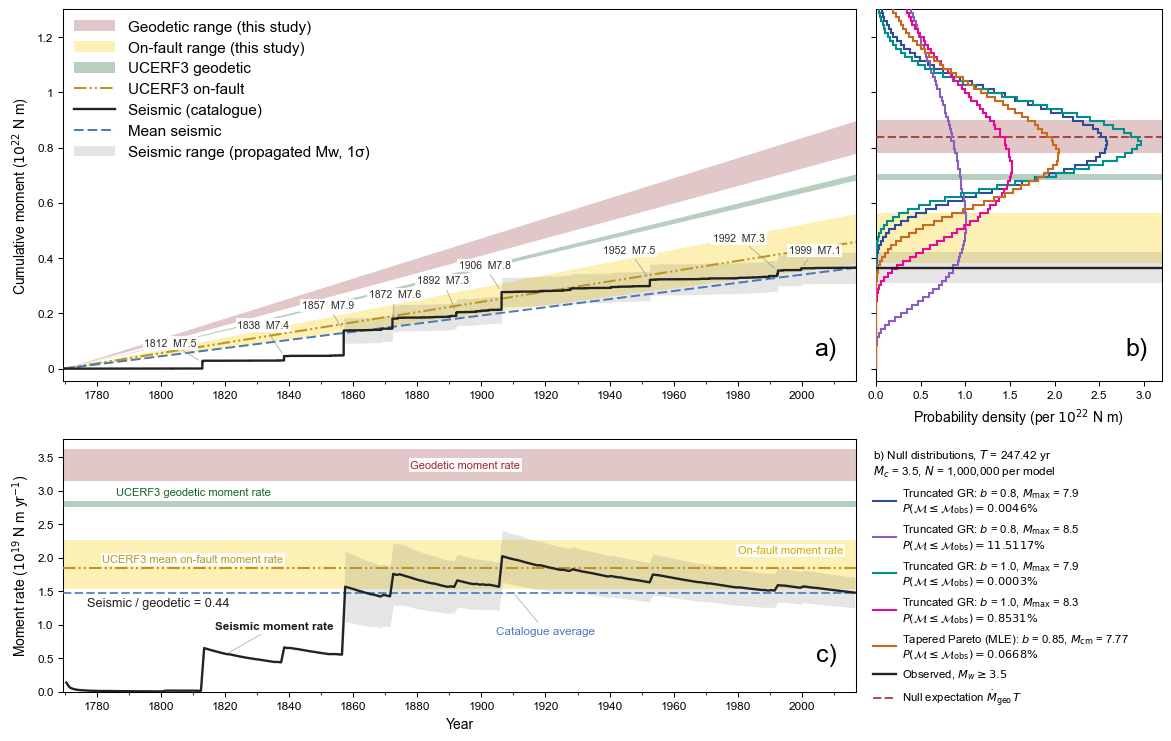

In [5]:
# ============================================================
# MATPLOTLIB STYLE
# ============================================================
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 8.0,
    "axes.linewidth": 0.75,
    "xtick.major.width": 0.75,
    "ytick.major.width": 0.75,
    "xtick.major.size": 3.5,
    "ytick.major.size": 3.5,
})
# UCERF3 total geodetic moment-rate range. 
GEO_RATE_UCERF3_LOWER = 2.76e19
GEO_RATE_UCERF3_UPPER = 2.85e19
UCERF3_GEO_ALPHA = 0.30
ucerf3_geo_moment_lower = (
    ucerf3_geo_moment_line * GEO_RATE_UCERF3_LOWER / GEO_RATE_UCERF3
)
ucerf3_geo_moment_upper = (
    ucerf3_geo_moment_line * GEO_RATE_UCERF3_UPPER / GEO_RATE_UCERF3
)
# ============================================================
# FIGURE
# ============================================================
# Panel a (top left) and panel b (top right) share the
# cumulative-moment y-axis; panel c (bottom left, the former
# panel b) shares the time axis with panel a. The bottom-right
# cell holds the panel-b legend.
fig = plt.figure(
    figsize=(11.6, 7.3),
    constrained_layout=True,
)
gs = fig.add_gridspec(
    2,
    2,
    height_ratios=[1.25, 0.85],
    width_ratios=[1.0, 0.36],
    hspace=0.03,
)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1], sharey=ax1)
ax3 = fig.add_subplot(gs[1, 0], sharex=ax1)
ax_leg = fig.add_subplot(gs[1, 1])
ax_leg.axis("off")
ax1.tick_params(axis="x", which="both", bottom=True, labelbottom=True)
# ============================================================
# PANEL A — CUMULATIVE MOMENT
# ============================================================
# Geodetic uncertainty range
ax1.fill_between(
    cal["date"],
    geo_moment_lower,
    geo_moment_upper,
    color=GEODETIC_FILL,
    alpha=0.55,
    linewidth=0,
    zorder=1,
)
# On-fault uncertainty range
ax1.fill_between(
    cal["date"],
    onfault_moment_lower,
    onfault_moment_upper,
    color=ONFAULT_FILL,
    alpha=ONFAULT_ALPHA,
    linewidth=0,
    zorder=1.5,
)
# UCERF3 total geodetic moment-rate range
ax1.fill_between(
    cal["date"],
    ucerf3_geo_moment_lower,
    ucerf3_geo_moment_upper,
    color=UCERF3_GEO_RATE_FILL,
    alpha=UCERF3_GEO_ALPHA,
    linewidth=0,
    zorder=3,
)
# UCERF3 on-fault moment rate
ax1.plot(
    cal["date"],
    ucerf3_onfault_moment_line,
    color=UCERF3_ONFAULT_FILL,
    linewidth=1.5,
    linestyle=UCERF3_ONFAULT_LS,
    zorder=4,
)
# Seismic cumulative uncertainty band
ax1.fill_between(
    cal["date"],
    cum_lower,
    cum_upper,
    color=SEISMIC_FILL,
    alpha=0.18,
    linewidth=0,
    step="post",
    zorder=2,
)
# Cumulative seismic moment
ax1.step(
    cal["date"],
    cal["cum_M0_Nm"],
    where="post",
    color=SEISMIC_COLOR,
    linewidth=1.7,
    zorder=5,
)
# Mean seismic-rate line
ax1.plot(
    cal["date"],
    avg_moment_line,
    color=AVG_RATE_COLOR,
    linewidth=1.4,
    linestyle=(0, (5, 2)),
    zorder=4,
)
# ============================================================
# X LIMITS
# ============================================================
ax1.set_xlim(
    cal["date"].iloc[0],
    cal["date"].iloc[-1]
)
# ============================================================
# EARTHQUAKE LABELS — MANUAL PLACEMENT
# ============================================================
E = 1e22
def _D(y, m, d):
    return pd.Timestamp(y, m, d)
earthquake_labels = [
    (
        "1812  M7.5",
        _D(1812, 12, 8),
        0.0230,
        _D(1803, 1, 1),
        0.075
    ),
    (
        "1838  M7.4",
        _D(1838, 6, 1),
        0.0456,
        _D(1832, 1, 1),
        0.140
    ),
    (
        "1857  M7.9",
        _D(1857, 1, 9),
        0.1373,
        _D(1852, 1, 1),
        0.210
    ),
    (
        "1872  M7.6",
        _D(1872, 3, 26),
        0.1768,
        _D(1873, 1, 1),
        0.250
    ),
    (
        "1892  M7.3",
        _D(1892, 2, 24),
        0.2021,
        _D(1888, 1, 1),
        0.300
    ),
    (
        "1906  M7.8",
        _D(1906, 4, 18),
        0.2764,
        _D(1901, 1, 1),
        0.355
    ),
    (
        "1952  M7.5",
        _D(1952, 7, 21),
        0.3212,
        _D(1946, 1, 1),
        0.410
    ),
    (
        "1992  M7.3",
        _D(1992, 6, 28),
        0.3540,
        _D(1980, 6, 1),
        0.455
    ),
    (
        "1999  M7.1",
        _D(1999, 10, 16),
        0.3633,
        _D(2004, 1, 1),
        0.410
    ),
]
for txt, ed, ey, ld, ly in earthquake_labels:
    ax1.annotate(
        txt,
        xy=(ed, ey * E),
        xytext=(ld, ly * E),
        textcoords="data",
        fontsize=7.6,
        color=ANNOTATION_COLOR,
        ha="center",
        va="bottom",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.9,
            pad=1.2
        ),
        arrowprops=dict(
            arrowstyle="-",
            lw=0.5,
            color=LEADER_COLOR,
            shrinkA=2,
            shrinkB=3
        ),
        zorder=8,
    )
# ============================================================
# MASTER LEGEND — PANEL A
# ============================================================
legend_handles = [
    Patch(
        facecolor=GEODETIC_FILL,
        edgecolor="none",
        alpha=0.55,
        label="Geodetic range (this study)"
    ),
    Patch(
        facecolor=ONFAULT_FILL,
        edgecolor="none",
        alpha=ONFAULT_ALPHA,
        label="On-fault range (this study)"
    ),
    Patch(
        facecolor=UCERF3_GEO_RATE_FILL,
        edgecolor="none",
        alpha=UCERF3_GEO_ALPHA,
        label="UCERF3 geodetic"
    ),
    Line2D(
        [0],
        [0],
        color=UCERF3_ONFAULT_FILL,
        linewidth=1.5,
        linestyle=UCERF3_ONFAULT_LS,
        label=r"UCERF3 on-fault"
    ),
    Line2D(
        [0],
        [0],
        color=SEISMIC_COLOR,
        linewidth=1.7,
        label="Seismic (catalogue)"
    ),
    Line2D(
        [0],
        [0],
        color=AVG_RATE_COLOR,
        linewidth=1.4,
        linestyle=(0, (5, 2)),
        label=r"Mean seismic"
    ),
    Patch(
        facecolor=SEISMIC_FILL,
        edgecolor="none",
        alpha=0.18,
        label="Seismic range (propagated Mw, 1σ)"
    ),
]
ax1.legend(
    handles=legend_handles,
    loc="upper left",
    frameon=False,
    handlelength=2.7,
    handletextpad=0.8,
    borderpad=0.2,
    labelspacing=0.45,
    fontsize=11,
)
# ============================================================
# PANEL A AXES
# ============================================================
ax1.set_ylabel(
    r"Cumulative moment ($10^{22}$ N m)"
)
ax1.yaxis.set_major_formatter(
    FuncFormatter(
        lambda v, pos: f"{v / 1e22:g}"
    )
)
# ax1.grid(axis="y", color=GRID_COLOR, linewidth=0.6)
ax1.grid(
    axis="x",
    visible=False
)
ax1.spines["top"].set_visible(True)
ax1.spines["right"].set_visible(True)
ax1.text(
    0.975,
    0.055,
    "a)",
    transform=ax1.transAxes,
    ha="right",
    va="bottom",
    fontsize=18
)
# ============================================================
# SHARED CUMULATIVE-MOMENT Y RANGE (PANELS A AND B)
# ============================================================
y_lo_a, y_hi_a = ax1.get_ylim()
y_top_ref = np.percentile(
    sim_S[NULL_DIST_YMAX_REFERENCE],
    NULL_DIST_YMAX_PERCENTILE
)
Y_SHARED = (
    y_lo_a,
    max(y_hi_a, np.ceil(y_top_ref / 1e21) * 1e21)
)
ax1.set_ylim(*Y_SHARED)
for key in MODELS:
    MC_RESULTS[key]["frac_above_plotted_range"] = float(
        np.mean(sim_S[key] > Y_SHARED[1])
    )
# ============================================================
# PANEL B — SIMULATED NULL DISTRIBUTIONS (CUMULATIVE MOMENT)
# ============================================================
S_edges = np.linspace(
    0.0,
    Y_SHARED[1],
    N_DENSITY_BINS + 1
)
max_density = 0.0
for key, mdl in MODELS.items():
    counts, _ = np.histogram(
        sim_S[key],
        bins=S_edges
    )
    density = counts / (
        len(sim_S[key])
        * np.diff(S_edges / 1e22)
    )
    max_density = max(max_density, density.max())
    ax2.stairs(
        density,
        S_edges,
        orientation="horizontal",
        baseline=None,
        color=mdl["color"],
        linewidth=1.5,
        zorder=4,
    )
# Geodetic uncertainty range at the end of the window
# (continuation of panel a's geodetic band at t = T_obs)
ax2.axhspan(
    GEO_LOWER * T_OBS,
    GEO_UPPER * T_OBS,
    color=GEODETIC_FILL,
    alpha=0.55,
    linewidth=0,
    zorder=1,
)
# On-fault uncertainty (yellow)
ax2.axhspan(
    ONFAULT_LOWER * T_OBS,
    ONFAULT_UPPER * T_OBS,
    color=ONFAULT_FILL,
    alpha=ONFAULT_ALPHA,
    linewidth=0,
    zorder=1.5,
)
# Observed seismic-moment uncertainty (gray)
ax2.axhspan(
    cum_lower.iloc[-1],
    cum_upper.iloc[-1],
    color=SEISMIC_FILL,
    alpha=0.18,
    linewidth=0,
    zorder=2,
)
# Expected cumulative moment under the null, G_true * T_obs
ax2.axhline(
    G_TRUE * T_OBS,
    color=GEODETIC_COLOR,
    linewidth=1.2,
    linestyle=(0, (5, 2)),
    zorder=3,
)
# Observed cumulative seismic moment (Mw >= Mc)
ax2.axhline(
    S_OBS,
    color=SEISMIC_COLOR,
    linewidth=1.7,
    zorder=5,
)
# UCERF3 total geodetic moment-rate range
ax2.axhspan(
    GEO_RATE_UCERF3_LOWER * T_OBS,
    GEO_RATE_UCERF3_UPPER * T_OBS,
    color=UCERF3_GEO_RATE_FILL,
    alpha=UCERF3_GEO_ALPHA,
    linewidth=0,
    zorder=3
)
ax2.set_xlim(
    0,
    max_density * 1.08
)
ax2.set_xlabel(
    r"Probability density (per $10^{22}$ N m)"
)
ax2.tick_params(
    labelleft=False
)
ax2.grid(
    axis="x",
    visible=False
)
ax2.spines["top"].set_visible(True)
ax2.spines["right"].set_visible(True)
ax2.text(
    0.95,
    0.055,
    "b)",
    transform=ax2.transAxes,
    ha="right",
    va="bottom",
    fontsize=18
)
# ============================================================
# PANEL B LEGEND (BOTTOM-RIGHT CELL)
# ============================================================
def _p_text(entry):
    if entry["p_low"] is not None:
        pct = 100.0 * entry["p_low"]
        return rf"$P(\mathcal{{M}} \leq \mathcal{{M}}_{{\rm obs}}) = {pct:.4f}\%$"
    pct_upper = 100.0 * entry["p_low_95upper"]
    return rf"$P(\mathcal{{M}} \leq \mathcal{{M}}_{{\rm obs}}) < {pct_upper:.4f}\%$ (95%)"
panel_b_handles = [
    Line2D(
        [0],
        [0],
        color=mdl["color"],
        linewidth=1.5,
        label=(
            f"{mdl['plot_label']}\n{_p_text(MC_RESULTS[key])}"
        )
    )
    for key, mdl in MODELS.items()
]
panel_b_handles += [
    Line2D(
        [0],
        [0],
        color=SEISMIC_COLOR,
        linewidth=1.7,
        label=rf"Observed, $M_w\geq{MC_COMPLETENESS:g}$"
    ),
    Line2D(
        [0],
        [0],
        color=GEODETIC_COLOR,
        linewidth=1.2,
        linestyle=(0, (5, 2)),
        label=r"Null expectation $\dot{M}_{\rm geo}\,T$"
    ),
]
ax_leg.legend(
    handles=panel_b_handles,
    loc="upper left",
    bbox_to_anchor=(-0.04, 1.0),
    frameon=False,
    handlelength=2.0,
    handletextpad=0.6,
    borderpad=0.2,
    labelspacing=0.55,
    fontsize=8.2,
    title=(
        f"b) Null distributions, $T$ = {T_OBS:.2f} yr\n"
        rf"$M_c$ = {MC_COMPLETENESS:g}, $N$ = {N_SIM:,} per model"
    ),
    title_fontsize=8.5,
    alignment="left",
)
# ============================================================
# PANEL C — EXPANDING-WINDOW RATE
# ============================================================
# Geodetic uncertainty range
ax3.axhspan(
    GEO_LOWER / 1e19,
    GEO_UPPER / 1e19,
    color=GEODETIC_FILL,
    alpha=0.55,
    linewidth=0,
    zorder=1
)
# On-fault uncertainty range
ax3.axhspan(
    ONFAULT_LOWER / 1e19,
    ONFAULT_UPPER / 1e19,
    color=ONFAULT_FILL,
    alpha=ONFAULT_ALPHA,
    linewidth=0,
    zorder=1.5
)
# UCERF3 total geodetic moment-rate range
ax3.axhspan(
    GEO_RATE_UCERF3_LOWER / 1e19,
    GEO_RATE_UCERF3_UPPER / 1e19,
    color=UCERF3_GEO_RATE_FILL,
    alpha=UCERF3_GEO_ALPHA,
    linewidth=0,
    zorder=3
)
# UCERF3 on-fault moment rate
ax3.axhline(
    ONFAULT_RATE_UCERF3 / 1e19,
    color=UCERF3_ONFAULT_FILL,
    linewidth=1.5,
    linestyle=UCERF3_ONFAULT_LS,
    zorder=4
)
# Expanding-window seismic uncertainty
ax3.fill_between(
    rate_dates,
    rate_lower / 1e19,
    rate_upper / 1e19,
    color=SEISMIC_FILL,
    alpha=0.18,
    linewidth=0,
    zorder=2
)
# Expanding-window seismic rate
ax3.plot(
    rate_dates,
    expanding_seismic_rate / 1e19,
    color=SEISMIC_COLOR,
    linewidth=1.7,
    zorder=5
)
# Catalogue-average rate
ax3.axhline(
    seismic_rate_mean / 1e19,
    color=AVG_RATE_COLOR,
    linewidth=1.2,
    linestyle=(0, (5, 2)),
    zorder=3
)
# ============================================================
# PANEL C LIMIT
# ============================================================
max_rate = max(
    np.nanmax(rate_upper / 1e19),
    GEO_UPPER / 1e19,
    ONFAULT_UPPER / 1e19,
    GEO_RATE_UCERF3_UPPER / 1e19
)
ax3.set_ylim(
    0,
    max_rate * 1.04
)
# ============================================================
# PANEL C ANNOTATIONS
# ============================================================
# Seismic / geodetic ratio
ax3.text(
    0.03,
    0.35,
    f"Seismic / geodetic = "
    f"{seismic_geodetic_ratio:.2f}",
    transform=ax3.transAxes,
    fontsize=9.2,
    color=SEISMIC_COLOR,
    ha="left",
    va="center",
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.9,
        pad=1.5
    ),
    zorder=10,
)
# Catalogue average
avg_y = seismic_rate_mean / 1e19
ax3.annotate(
    "Catalogue average",
    xy=(
        pd.Timestamp(1910, 1, 1),
        avg_y
    ),
    xytext=(
        pd.Timestamp(1920, 1, 1),
        avg_y - 0.5
    ),
    textcoords="data",
    fontsize=8.5,
    color=AVG_RATE_COLOR,
    ha="center",
    va="top",
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.9,
        pad=1.2
    ),
    arrowprops=dict(
        arrowstyle="-",
        lw=0.45,
        color=LEADER_COLOR,
        shrinkA=2,
        shrinkB=2
    ),
    zorder=10,
)
# Expanding time window
method_idx = int(
    np.argmin(
        np.abs(
            rate_years - 1820
        )
    )
)
ax3.annotate(
    "Seismic moment rate",
    xy=(
        rate_dates[method_idx],
        expanding_seismic_rate[method_idx] / 1e19
    ),
    xytext=(
        pd.Timestamp(1817, 1, 1),
        0.9
    ),
    textcoords="data",
    fontsize=8.5,
    fontweight="bold",
    color=TEXT_GREY_ANNOTATION,
    ha="left",
    va="bottom",
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.85,
        pad=1.0
    ),
    arrowprops=dict(
        arrowstyle="-",
        lw=0.45,
        color=LEADER_COLOR,
        shrinkA=2,
        shrinkB=2
    ),
    zorder=10,
)
# On-fault rate label
ax3.text(
    pd.Timestamp(1980, 1, 1),
    (ONFAULT_RATE / 1e19) + 0.3,
    "On-fault moment rate",
    color=ONFAULT_COLOR_ANNOTATION,
    fontsize=8.0,
    ha="left",
    va="bottom",
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.90,
        pad=1.2
    ),
    zorder=10,
)
# Geodetic rate label
ax3.text(
    pd.Timestamp(1895, 1, 1),
    (GEO_RATE / 1e19) - 0.08,
    "Geodetic moment rate",
    color=GEODETIC_COLOR,
    fontsize=8.0,
    ha="center",
    va="bottom",
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.90,
        pad=1.2
    ),
    zorder=10,
)
# UCERF3 on-fault rate label
ax3.text(
    pd.Timestamp(1810, 1, 1),
    (ONFAULT_RATE_UCERF3 / 1e19) + 0.05,
    "UCERF3 mean on-fault moment rate",
    color=UCERF3_ONFAULT_FILL,
    fontsize=8.0,
    ha="center",
    va="bottom",
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.90,
        pad=1.2
    ),
    zorder=10,
)
# UCERF3 geodetic rate label
ax3.text(
    pd.Timestamp(1810, 1, 1),
    ((GEO_RATE_UCERF3_LOWER + GEO_RATE_UCERF3_UPPER) / 2e19) + 0.1,
    "UCERF3 geodetic moment rate",
    color=UCERF3_GEO_RATE_FILL,
    fontsize=8.0,
    ha="center",
    va="bottom",
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.90,
        pad=1.2
    ),
    zorder=10,
)
# ============================================================
# PANEL C AXES
# ============================================================
ax3.set_ylabel(
    r"Moment rate ($10^{19}$ N m yr$^{-1}$)"
)
ax3.set_xlabel(
    "Year"
)
# ax3.grid(axis="y", color=GRID_COLOR, linewidth=0.6)
ax3.grid(
    axis="x",
    visible=False
)
ax3.spines["top"].set_visible(True)
ax3.spines["right"].set_visible(True)
ax3.text(
    0.975,
    0.10,
    "c)",
    transform=ax3.transAxes,
    ha="right",
    va="bottom",
    fontsize=18
)
# ============================================================
# SHARED X AXIS
# ============================================================
ax3.xaxis.set_major_locator(
    mdates.YearLocator(20)
)
ax3.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y")
)
ax3.xaxis.set_minor_locator(
    mdates.YearLocator(10)
)
# ============================================================
# SAVE
# ============================================================
fig.savefig(
    OUT_PNG,
    dpi=400,
    bbox_inches="tight"
)
fig.savefig(
    OUT_PDF,
    bbox_inches="tight"
)
# ============================================================
# DISPLAY
# ============================================================
plt.show()


In [6]:
# ============================================================
# PRINT SUMMARY
# ============================================================

print("=" * 72)
print(f"MUELLER C2 — CALIFORNIA MOMENT BUDGET (Mw >= Mc = {MC_COMPLETENESS})")
print("=" * 72)

print(
    f"Parsed C2 events:             "
    f"{len(df):,}"
)

print(
    f"California polygon events:    "
    f"{len(cal_all):,}"
)

print(
    f"  of which Mw >= Mc:          "
    f"{len(cal):,}"
)

print(
    f"Catalogue period:             "
    f"{cal_all.date.iloc[0].date()} to "
    f"{cal_all.date.iloc[-1].date()}"
)

print(
    f"Duration:                     "
    f"{duration:.2f} yr"
)

print(
    f"Total seismic moment:         "
    f"{total_moment:.3e} N m"
)

print(
    f"Mean seismic moment rate:     "
    f"{seismic_rate_mean:.3e} N m/yr"
)

print(
    f"Full-catalogue 1-sigma:       "
    f"{seismic_rate_sigma_final:.3e} N m/yr"
)

print(
    f"Geodetic reference (midpoint):"
    f"{GEO_RATE:.3e} N m/yr"
)

print(
    f"Geodetic best-fit (reference):"
    f"{GEO_BEST:.3e} N m/yr"
)

print(
    f"Geodetic lower bound:         "
    f"{GEO_LOWER:.3e} N m/yr"
)

print(
    f"Geodetic upper bound:         "
    f"{GEO_UPPER:.3e} N m/yr"
)

print(
    f"On-fault moment rate:         "
    f"{ONFAULT_RATE:.3e} N m/yr"
)

print(
    f"On-fault lower bound:         "
    f"{ONFAULT_LOWER:.3e} N m/yr"
)

print(
    f"On-fault upper bound:         "
    f"{ONFAULT_UPPER:.3e} N m/yr"
)

# off-fault bounds for completeness (not used elsewhere)

print(
    f"Off-fault lower bound:        "
    f"{OFFFAULT_LOWER:.3e} N m/yr"
)

print(
    f"Off-fault upper bound:        "
    f"{OFFFAULT_UPPER:.3e} N m/yr"
)

print(
    f"UCERF3 total moment rate:     "
    f"{GEO_RATE_UCERF3:.3e} N m/yr"
)

print(
    f"UCERF3 on-fault moment rate:  "
    f"{ONFAULT_RATE_UCERF3:.3e} N m/yr"
)

print(
    f"Seismic / geodetic ratio:     "
    f"{seismic_geodetic_ratio:.3f}"
)

print(
    f"Seismic release fraction:     "
    f"{seismic_percentage:.1f}%"
)

print(
    "\nExpanding-window formulation:"
)

print(
    "  rate(t)  = cumulative M0 / elapsed time"
)

print(
    "  sigma(t) = sqrt(sum(sigma_M0^2)) / elapsed time"
)

print(
    "  sigma_M0 = ln(10) * 1.5 * M0 * sigma_Mw"
)

print(
    "\nLargest included events:"
)

print(
    cal.nlargest(12, "Mw")[
        [
            "Year",
            "Month",
            "Day",
            "Mw",
            "Longitude",
            "Latitude",
            "M0_Nm"
        ]
    ].to_string(index=False)
)

print("\nMonte Carlo null test (panel b):")
print(summary_df.to_string(index=False))

print(f"\nFraction of each null distribution above panel b's axis top ({Y_SHARED[1]:.2e} N m):")
for key in MODELS:
    print(f"  {key:20s} {100 * MC_RESULTS[key]['frac_above_plotted_range']:.2f}%")

print(
    "\nSaved:"
)

print(OUT_PNG)
print(OUT_PDF)

MUELLER C2 — CALIFORNIA MOMENT BUDGET (Mw >= Mc = 3.5)
Parsed C2 events:             96,835
California polygon events:    68,786
  of which Mw >= Mc:          10,340
Catalogue period:             1769-07-28 to 2016-12-28
Duration:                     247.42 yr
Total seismic moment:         3.653e+21 N m
Mean seismic moment rate:     1.476e+19 N m/yr
Full-catalogue 1-sigma:       2.272e+18 N m/yr
Geodetic reference (midpoint):3.390e+19 N m/yr
Geodetic best-fit (reference):3.230e+19 N m/yr
Geodetic lower bound:         3.150e+19 N m/yr
Geodetic upper bound:         3.630e+19 N m/yr
On-fault moment rate:         1.730e+19 N m/yr
On-fault lower bound:         1.540e+19 N m/yr
On-fault upper bound:         2.270e+19 N m/yr
Off-fault lower bound:        1.360e+19 N m/yr
Off-fault upper bound:        1.610e+19 N m/yr
UCERF3 total moment rate:     2.797e+19 N m/yr
UCERF3 on-fault moment rate:  1.853e+19 N m/yr
Seismic / geodetic ratio:     0.436
Seismic release fraction:     43.6%

Expanding-w

## Sensitivity to one additional large earthquake

How $P(S\le S_{\rm obs})$ would change if the catalogue contained one more large event, and the single-event
magnitude that would raise it to 5 % (the 5th percentile of each null distribution minus $S_{\rm obs}$).

In [7]:
# ============================================================
# SENSITIVITY TEST — EFFECT OF ONE ADDITIONAL LARGE EARTHQUAKE
# ============================================================

TARGET_P = 0.05
TEST_MW = [7.8, 8.0]

def mw_to_m0(Mw):
    """Moment magnitude Mw -> seismic moment M0 [N m]."""
    return 10.0 ** (1.5 * Mw + 9.1)


def m0_to_mw(M0):
    """Seismic moment M0 [N m] -> moment magnitude Mw."""
    return (np.log10(M0) - 9.1) / 1.5


rows = []

for key, mdl in MODELS.items():

    S = sim_S[key]

    # --------------------------------------------------------
    # Current observed catalogue
    # --------------------------------------------------------
    p_current = np.mean(S <= S_OBS)

    row = {
        "model": mdl["plot_label"],
        "current P (%)": 100.0 * p_current,
    }

    # --------------------------------------------------------
    # Add hypothetical earthquakes
    # --------------------------------------------------------
    for Mw in TEST_MW:

        M0_added = mw_to_m0(Mw)
        S_new = S_OBS + M0_added
        p_new = np.mean(S <= S_new)

        row[f"P after Mw {Mw:.1f} (%)"] = 100.0 * p_new

    # --------------------------------------------------------
    # Find cumulative moment corresponding to 5th percentile
    # --------------------------------------------------------
    S_target = np.quantile(S, TARGET_P)

    # Extra moment needed to move observed catalogue there
    delta_M0 = S_target - S_OBS

    if delta_M0 > 0:
        Mw_needed = m0_to_mw(delta_M0)
    else:
        Mw_needed = np.nan

    row["S at 5% (N m)"] = S_target
    row["additional M0 for 5% (N m)"] = max(delta_M0, 0.0)
    row["Mw needed for 5%"] = Mw_needed

    rows.append(row)


# ============================================================
# RESULTS TABLE
# ============================================================

sensitivity_df = pd.DataFrame(rows)

display(sensitivity_df)


# ============================================================
# CLEAN TEXT SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("SENSITIVITY TO ONE ADDITIONAL LARGE EARTHQUAKE")
print("=" * 75)

print(f"\nObserved cumulative moment: {S_OBS:.4e} N m")
print(f"Target lower-tail probability: {100 * TARGET_P:.1f}%")

for Mw in TEST_MW:
    print(
        f"Mw {Mw:.1f}: M0 = {mw_to_m0(Mw):.4e} N m, "
        f"new S_obs = {S_OBS + mw_to_m0(Mw):.4e} N m"
    )

print()

for _, row in sensitivity_df.iterrows():

    print(row["model"])
    print(f"  Current:       P = {row['current P (%)']:.4f}%")

    for Mw in TEST_MW:
        print(
            f"  + Mw {Mw:.1f}:      "
            f"P = {row[f'P after Mw {Mw:.1f} (%)']:.4f}%"
        )

    if np.isnan(row["Mw needed for 5%"]):
        print(
            f"  Already above the {100 * TARGET_P:.1f}% "
            "lower-tail threshold."
        )
    else:
        print(
            f"  Mw required to reach {100 * TARGET_P:.1f}%: "
            f"{row['Mw needed for 5%']:.2f}"
        )

    print()

,model,current P (%),P after Mw 7.8 (%),P after Mw 8.0 (%),S at 5% (N m),additional M0 for 5% (N m),Mw needed for 5%
0,"Truncated GR: $b$ = 0.8, $M_{\max}$ = 7.9",0.0046,0.0626,0.4684,6.009494e+21,2.356647e+21,8.181530
1,"Truncated GR: $b$ = 0.8, $M_{\max}$ = 8.5",11.5117,17.3338,23.5245,2.812991e+21,0.000000e+00,NaN
2,"Truncated GR: $b$ = 1.0, $M_{\max}$ = 7.9",0.0003,0.0043,0.0978,6.288394e+21,2.635546e+21,8.213914
3,"Truncated GR: $b$ = 1.0, $M_{\max}$ = 8.3",0.8531,3.2115,7.6692,4.574378e+21,9.215301e+20,7.909673
4,"Tapered Pareto (MLE): $b$ = 0.85, $M_{\rm cm}$...",0.0668,0.5025,2.0829,5.426992e+21,1.774144e+21,8.099326



SENSITIVITY TO ONE ADDITIONAL LARGE EARTHQUAKE

Observed cumulative moment: 3.6528e+21 N m
Target lower-tail probability: 5.0%
Mw 7.8: M0 = 6.3096e+20 N m, new S_obs = 4.2838e+21 N m
Mw 8.0: M0 = 1.2589e+21 N m, new S_obs = 4.9118e+21 N m

Truncated GR: $b$ = 0.8, $M_{\max}$ = 7.9
  Current:       P = 0.0046%
  + Mw 7.8:      P = 0.0626%
  + Mw 8.0:      P = 0.4684%
  Mw required to reach 5.0%: 8.18

Truncated GR: $b$ = 0.8, $M_{\max}$ = 8.5
  Current:       P = 11.5117%
  + Mw 7.8:      P = 17.3338%
  + Mw 8.0:      P = 23.5245%
  Already above the 5.0% lower-tail threshold.

Truncated GR: $b$ = 1.0, $M_{\max}$ = 7.9
  Current:       P = 0.0003%
  + Mw 7.8:      P = 0.0043%
  + Mw 8.0:      P = 0.0978%
  Mw required to reach 5.0%: 8.21

Truncated GR: $b$ = 1.0, $M_{\max}$ = 8.3
  Current:       P = 0.8531%
  + Mw 7.8:      P = 3.2115%
  + Mw 8.0:      P = 7.6692%
  Mw required to reach 5.0%: 7.91

Tapered Pareto (MLE): $b$ = 0.85, $M_{\rm cm}$ = 7.77
  Current:       P = 0.0668%
  + 

## Derived statistics 

Quantities quoted in the manuscript summary that are not printed above: the ratio against each geodetic
reference, the share of moment carried by the largest events, the range of the expanding-window rate, and an
exact Poisson 95 % interval on each Monte Carlo hit count.

In [8]:
# ============================================================
# DERIVED STATISTICS
# ============================================================

from scipy import stats as _st

print(f"Seismic rate = {seismic_rate_mean:.3e} +/- {seismic_rate_sigma_final:.3e} N m/yr "
      f"({100 * seismic_rate_sigma_final / seismic_rate_mean:.1f}% 1-sigma)")
for name, ref in [("geodetic midpoint", GEO_RATE), ("geodetic min", GEO_LOWER),
                  ("geodetic max", GEO_UPPER), ("geodetic best fit", GEO_BEST),
                  ("UCERF3 total", GEO_RATE_UCERF3), ("on-fault best", ONFAULT_RATE),
                  ("on-fault min", ONFAULT_LOWER), ("on-fault max", ONFAULT_UPPER),
                  ("UCERF3 on-fault", ONFAULT_RATE_UCERF3)]:
    print(f"  seismic / {name:18s} ({ref:.3e}) = {seismic_rate_mean / ref:.3f}")

# Share of the catalogue moment in the largest events
for m_thr in [7.0, 7.3, 7.5]:
    sel = cal["Mw"] >= m_thr
    print(f"Mw >= {m_thr}: {sel.sum()} events carry {100 * cal.loc[sel, 'M0_Nm'].sum() / S_OBS:.1f}% of S_obs")

# Expanding-window rate range
for y0 in [1857, 1900]:
    sel = rate_years >= y0
    print(f"Expanding-window rate, {y0}-{rate_years[-1]}: "
          f"{np.nanmin(expanding_seismic_rate[sel]) / 1e19:.2f} - {np.nanmax(expanding_seismic_rate[sel]) / 1e19:.2f} "
          f"x 1e19 N m/yr")
print(f"Expanding-window rate never exceeds the geodetic minimum: "
      f"{bool(np.nanmax(expanding_seismic_rate[rate_years >= 1857]) < GEO_LOWER)}")

# Exact (Garwood) Poisson 95% interval on each hit count
print("\nP(S <= S_obs) with exact 95% interval on the hit count:")
for key in MODELS:
    k = MC_RESULTS[key]["n_hits"]
    lo = 0.0 if k == 0 else _st.chi2.ppf(0.025, 2 * k) / 2
    hi = _st.chi2.ppf(0.975, 2 * k + 2) / 2
    MC_RESULTS[key]["p_low_95ci"] = [lo / N_SIM, hi / N_SIM]
    print(f"  {key:20s} {k:7d} hits  P = {k / N_SIM:.2e}  (95% CI {lo / N_SIM:.1e} - {hi / N_SIM:.1e})")

Seismic rate = 1.476e+19 +/- 2.272e+18 N m/yr (15.4% 1-sigma)
  seismic / geodetic midpoint  (3.390e+19) = 0.436
  seismic / geodetic min       (3.150e+19) = 0.469
  seismic / geodetic max       (3.630e+19) = 0.407
  seismic / geodetic best fit  (3.230e+19) = 0.457
  seismic / UCERF3 total       (2.797e+19) = 0.528
  seismic / on-fault best      (1.730e+19) = 0.853
  seismic / on-fault min       (1.540e+19) = 0.959
  seismic / on-fault max       (2.270e+19) = 0.650
  seismic / UCERF3 on-fault    (1.853e+19) = 0.797
Mw >= 7.0: 13 events carry 80.5% of S_obs
Mw >= 7.3: 7 events carry 70.0% of S_obs
Mw >= 7.5: 5 events carry 62.6% of S_obs
Expanding-window rate, 1857-2016: 1.42 - 2.02 x 1e19 N m/yr
Expanding-window rate, 1900-2016: 1.48 - 2.02 x 1e19 N m/yr
Expanding-window rate never exceeds the geodetic minimum: True

P(S <= S_obs) with exact 95% interval on the hit count:
  tgr_b0.8_mmax7.9          46 hits  P = 4.60e-05  (95% CI 3.4e-05 - 6.1e-05)
  tgr_b0.8_mmax8.5      115117 hits  

In [9]:
# ============================================================
# SAVE MONTE CARLO RESULTS
# ============================================================

with open(RESULTS_JSON, "w") as f:
    json.dump(dict(
        G_TRUE=float(G_TRUE), T_OBS=float(T_OBS), S_OBS=float(S_OBS), Mc=MC_COMPLETENESS,
        N_SIM=N_SIM, SEED=SEED, tapered_pareto_fit=tp_fit, models=MC_RESULTS,
    ), f, indent=2, default=float)

print(f"Saved: {RESULTS_JSON}")
print(f"Total notebook wall time: {time.time() - T_START:.0f} s")

Saved: ../output_data/catalog_analysis_mcmc/mc_null_cumulative_moment_results.json
Total notebook wall time: 5 s


## Results summary

All values are from the outputs above (run from scratch; $10^6$ catalogues per model). 

**Observed budget ($M_w\ge3.5$, 28 Jul 1769 – 28 Dec 2016, $T_{\rm obs}$ = 247.42 yr).** 10,340 of 68,786
in-polygon events; $S_{\rm obs}=3.65\times10^{21}$ N m. Average seismic moment rate
$1.48\pm0.23\times10^{19}$ N m/yr (1σ, 15 %).

| Reference rate ($10^{19}$ N m/yr) | Value | Seismic / reference |
|---|---|---|
| Geodetic, midpoint (null and ratio) | 3.39 | **0.44** |
| Geodetic, range | 3.15 – 3.63 | 0.47 – 0.41 |
| Geodetic, best-fit model | 3.23 | 0.46 |
| UCERF3 total | 3.03 | 0.49 |
| On-fault, best fit (range) | 1.73 (1.54 – 2.27) | 0.85 (0.96 – 0.65) |
| UCERF3 on-fault | 1.93 | 0.76 |

The seven $M_w\ge7.3$ events carry 70 % of $S_{\rm obs}$ (13 events with $M_w\ge7.0$ carry 80 %). After 1857 the
expanding-window rate stays between 1.42 and 2.02 $\times10^{19}$ N m/yr, always below the geodetic minimum.

**Null test** ($G_{\rm true}$ = 3.39e19 N m/yr, $G_{\rm true}T$ = 8.39e21 N m; simulated means agree to < 0.06 %).

| Model | Hits / $10^6$ | $P(S\le S_{\rm obs})$ | 95 % CI | + $M_w$ 7.8 | + $M_w$ 8.0 | $M_w$ for 5 % |
|---|---|---|---|---|---|---|
| TGR $b$ 0.8, $M_{\max}$ 7.9 | 46 | 4.6e-5 | 3.4e-5 – 6.1e-5 | 0.063 % | 0.47 % | 8.18 |
| TGR $b$ 0.8, $M_{\max}$ 8.5 | 115,117 | 0.115 | 0.114 – 0.116 | 17.3 % | 23.5 % | — |
| TGR $b$ 1.0, $M_{\max}$ 7.9 | 3 | 3.0e-6 | 6.2e-7 – 8.8e-6 | 0.0043 % | 0.098 % | 8.21 |
| TGR $b$ 1.0, $M_{\max}$ 8.3 | 8,531 | 8.5e-3 | 8.4e-3 – 8.7e-3 | 3.2 % | 7.7 % | 7.91 |
| Tapered Pareto, $b$ 0.85, $m_{\rm cm}$ 7.77 | 668 | 6.7e-4 | 6.2e-4 – 7.2e-4 | 0.50 % | 2.1 % | 8.10 |

Only the $M_{\max}$ = 8.5 model makes the observed deficit plausible at the 5 % level. For models whose upper
tail is close to the largest observed event, reaching 5 % requires one additional earthquake of
$M_w\approx$ 7.9–8.2. 